# Portfolio Optimization & Risk Management System

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import scipy.stats as stat
from scipy.optimize import minimize

## Module 1 - Data Acquisition, Preprocessing & Portfolio Construction

In [2]:
def get_market_data(ticker, start, end):
  price = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)['Close']
  valid_count = price.notna().sum()
  if valid_count.min() < 0.9 * valid_count.max():
    print(f' Warning! Uneven data history: {valid_count}')
  price = price.dropna()
  print(f'Using {len(price)} trading days from {price.index.min().date()} to {price.index.max().date()}')
  daily_returns = price.pct_change().dropna()
  return daily_returns

tickers = ['BND', 'GLD', 'EFA', 'SPY', 'VNQ']
start_date = '2007-12-31'
end_date = '2026-01-01'

daily_returns = get_market_data(tickers, start=start_date, end=end_date)

Using 4530 trading days from 2007-12-31 to 2025-12-31


In [3]:
split_idx = int(len(daily_returns) * 0.8)

train_returns = daily_returns.iloc[:split_idx]
test_returns = daily_returns.iloc[split_idx:]

train_mu = train_returns.mean() * 252
train_cov = train_returns.cov() * 252

print(f'Training Data: {len(train_returns)} trading days from {train_returns.index.min().date()} to {train_returns.index.max().date()}')
print(f'Testing Data: {len(test_returns)} trading days from {test_returns.index.min().date()} to {test_returns.index.max().date()}')

Training Data: 3623 trading days from 2008-01-02 to 2022-05-20
Testing Data: 906 trading days from 2022-05-23 to 2025-12-31


In [4]:
def weight_strategy(returns, mu, cov, rf=0.0):
    n_assets = len(returns.columns)
    bounds = ((0, 0.4),) * n_assets  # Max of 40% per asset
    constraints = {'type' : 'eq', 'fun' : lambda w: np.sum(w) - 1}

    # -- Equal Weights --
    eq_w = np.repeat(1/n_assets, n_assets)

    # -- Min Variance Weights --
    a = minimize(lambda w: w.T @ cov @ w,
                 x0 = eq_w, method = 'SLSQP', bounds = bounds, constraints = constraints)

    # -- Max Sharpe Weights --
    b = minimize(lambda w: -((w.T @ mu) - rf) / np.sqrt(w.T @ cov @ w),
                 x0 = eq_w, method = 'SLSQP', bounds = bounds, constraints = constraints)

    # -- Min CVaR Weights --
    def min_cvar(w):
        p_ret = returns.values @ w
        var = np.quantile(p_ret, 0.05)  # for a 95% confidence
        return -(p_ret[p_ret <= var].mean())

    c = minimize(min_cvar,
                 x0 = eq_w, method = 'SLSQP', bounds = bounds, constraints = constraints)

    # -- Risk Parity --
    def risk_parity(w):
        port_vol = np.sqrt(w.T @ cov @ w)
        marginal_risk = (cov @ w) / port_vol
        risk_contrib = w * marginal_risk
        target_risk = port_vol / n_assets
        return np.sum((risk_contrib - target_risk) ** 2)

    d = minimize(risk_parity,
                 x0 = eq_w, method = 'SLSQP', bounds = bounds, constraints = constraints)

    opt_results = {
        'Min Variance' : a,
        'Max Sharpe' : b,
        'Min CVaR' : c,
        'Risk Parity' : d
    }

    for name, w in opt_results.items():
      if not w.success:
        print(f'Breach: [{name}] Optimizer Failed to Converge! Message: {w.message}')


    return {
        'Equal Weights' : eq_w,
        'Min Variance' : a.x,
        'Max Sharpe' : b.x,
        'Min CVaR' : c.x,
        'Risk Parity' : d.x
    }

weights_strat = weight_strategy(train_returns, train_mu, train_cov)

index = [f'{t} Weight (%)' for t in train_returns.columns]
weight_df = pd.DataFrame(weights_strat, index=index).T
weight_df.style.format('{:.2%}')

,BND Weight (%),EFA Weight (%),GLD Weight (%),SPY Weight (%),VNQ Weight (%)
Equal Weights,20.00%,20.00%,20.00%,20.00%,20.00%
Min Variance,40.00%,0.00%,33.05%,26.95%,0.00%
Max Sharpe,40.00%,0.00%,26.37%,33.63%,0.00%
Min CVaR,40.00%,0.00%,32.95%,27.05%,0.00%
Risk Parity,40.00%,12.27%,25.21%,13.50%,9.02%


## Module 2 - In-Sample Portfolio Risk & Performance

In [5]:
def portfolio_risk(returns, weights, c=0.95):
    p = 1 - c
    p_ret = returns.values @ weights
    var = np.quantile(p_ret, p)
    cvar = p_ret[p_ret <= var].mean()
    return -var, -cvar

def portfolio_performance(returns, weights, mu, cov, rf=0.0):
    ann_ret = weights.T @ mu
    ann_vol = np.sqrt(weights.T @ cov @ weights)
    ann_sharpe = (ann_ret - rf) / ann_vol

    p_ret = returns @ weights
    cum_ret = (1 + p_ret).cumprod()
    peak = cum_ret.cummax()
    max_dd = ((cum_ret / peak) - 1).min()
    return ann_ret, ann_vol, ann_sharpe, max_dd

summary_data = []
for name, weight in weights_strat.items():
    var, cvar = portfolio_risk(train_returns, weight)
    ann_ret, ann_vol, ann_sharpe, max_dd = portfolio_performance(train_returns, weight, train_mu, train_cov)

    row_dict = {'Strategy' : name}
    row_dict.update({
        'Daily VaR (95%)' : var,
        'Daily CVaR (95%)' : cvar,
        'Max Drawdown' : max_dd,
        'Annualized Mean Return' : ann_ret,
        'Annual Volatility' : ann_vol,
        'Annual Sharpe' : ann_sharpe
    })
    summary_data.append(row_dict)

in_sample_df = pd.DataFrame(summary_data).set_index('Strategy')
formats = {col : '{:.2%}' for col in in_sample_df.columns}
formats['Annual Sharpe'] = '{:.2f}'
in_sample_df.style.format(formats)


,Daily VaR (95%),Daily CVaR (95%),Max Drawdown,Annualized Mean Return,Annual Volatility,Annual Sharpe
Strategy,,,,,,
Equal Weights,1.28%,2.26%,-38.54%,7.50%,14.65%,0.51
Min Variance,0.81%,1.27%,-19.85%,6.36%,8.60%,0.74
Max Sharpe,0.80%,1.30%,-21.91%,6.64%,8.79%,0.76
Min CVaR,0.81%,1.27%,-19.87%,6.36%,8.60%,0.74
Risk Parity,0.85%,1.43%,-25.49%,6.04%,9.59%,0.63


## Module 3 - Portfolio Risk Composition

In [6]:
def risk_composition(weights, cov):
    port_vol = np.sqrt(weights.T @ cov @ weights)
    pct_risk_contrib = (weights * (cov @ weights)) / port_vol ** 2
    return pct_risk_contrib

risk_decomposition = []
for name, weight in weights_strat.items():
    risk_share = risk_composition(weight, train_cov)

    row_dict = {'Strategy' : name}
    row_dict.update({f'{t} Risk Share (%)' : r_share * 100 for r_share, t in zip(risk_share, train_returns.columns)})
    risk_decomposition.append(row_dict)

risk_share_df = pd.DataFrame(risk_decomposition).set_index('Strategy')
risk_share_df.style.format('{:.2f}')

,BND Risk Share (%),EFA Risk Share (%),GLD Risk Share (%),SPY Risk Share (%),VNQ Risk Share (%)
Strategy,,,,,
Equal Weights,0.43,28.34,7.50,25.31,38.42
Min Variance,7.69,0.00,50.84,41.47,0.00
Max Sharpe,6.53,0.00,31.77,61.70,0.00
Min CVaR,7.68,0.00,50.57,41.75,0.00
Risk Parity,5.31,23.87,26.00,22.68,22.14


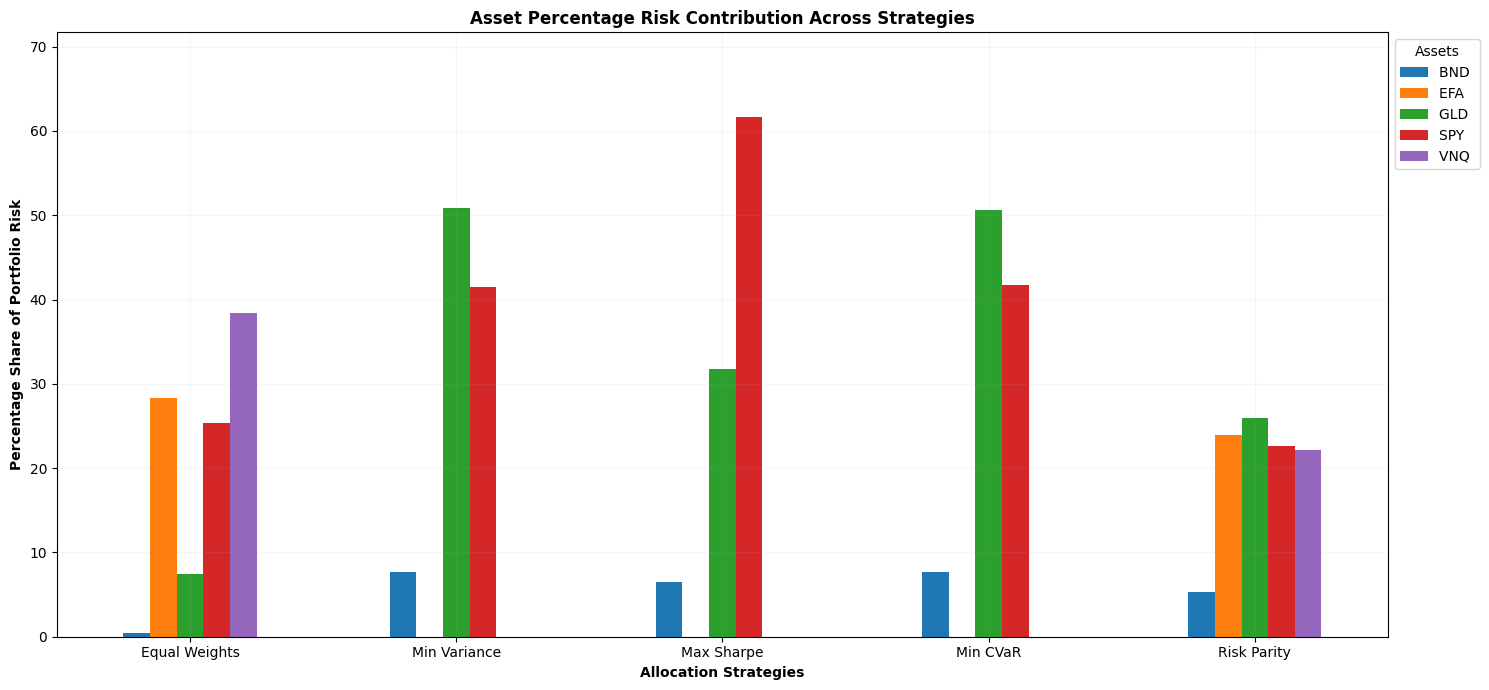

In [7]:
fig, ax = plt.subplots(figsize = (15, 7), dpi=100)

risk_share_df.plot(kind='bar', ax=ax)

ax.set_title('Asset Percentage Risk Contribution Across Strategies', fontsize=12, fontweight='bold')
ax.set_ylabel('Percentage Share of Portfolio Risk', fontsize=10, fontweight='semibold')
ax.set_xlabel('Allocation Strategies', fontsize=10, fontweight='semibold')
ax.set_ylim(0, risk_share_df.values.max() + 10)

plt.xticks(rotation=0)

clean_label = [col.replace('Risk Share (%)', '') for col in risk_share_df.columns]
ax.legend(clean_label, title='Assets', bbox_to_anchor=(1,1), loc='upper left', fontsize=10)

ax.grid(True, alpha=0.1)
plt.tight_layout()
plt.show()

## Module 4 - Portfolio Implementation & Trading Frictions

In [8]:
def friction(returns, w, freq='M', bps_cost=5):
    period  = pd.to_datetime(returns.index).to_period(freq)

    asset_growth  = (1 + returns).groupby(period).cumprod()      # asset growth since last rebalance
    port_growth  = asset_growth @ w                             # portfolio growth since last rebalance

    prev_growth = port_growth.groupby(period).shift(1).fillna(1.0)
    gross_daily = port_growth / prev_growth - 1.0

    drifted_w = asset_growth.mul(w).div(port_growth, axis=0)           # daily drifted weights
    drift = (drifted_w - w).abs()

    is_rebal_day = pd.Series(period, index=returns.index).ne(pd.Series(period, index=returns.index).shift(-1))
    is_rebal_day.iloc[-1] = False

    one_way_turnover = 0.5 * drift.sum(axis=1) * is_rebal_day
    cost = 2 * bps_cost / 10_000 * one_way_turnover
    net_daily = gross_daily - cost

    net_curve = (1 + net_daily).cumprod()
    return {
        'cum_gross':      (1 + gross_daily).prod() - 1,
        'cum_net':        net_curve.iloc[-1] - 1,
        'annual_turnover': one_way_turnover.sum() / (len(returns) / 252),
        'max_drawdown':   (net_curve / net_curve.cummax() - 1).min(),
        'max_drift':      drift.max().max(),
        'avg_drift':      drift.mean(axis=1).mean(),
        'net_returns': net_daily
    }

In [9]:
is_dashboard_res = {}
for name, weight in weights_strat.items():
    res = friction(train_returns, weight)
    is_dashboard_res[name] = {
        'Daily Rebalanced (Gross)': (1 + train_returns @ weight).prod() - 1,
        'Monthly Rebal (Gross)':       res['cum_gross'],
        'Monthly Rebal (Net)':         res['cum_net'],
        'Pure Buy & Hold (Gross)':     (1 + train_returns).prod() @ weight - 1,
        'Ann. Turnover (One-Way)':     res['annual_turnover'],
        'Max Drawdown (Net)':          res['max_drawdown'],
        'Max Asset Drift':             res['max_drift'],
        'Avg Asset Drift':             res['avg_drift']
    }

is_friction_df = pd.DataFrame(is_dashboard_res).T
is_friction_df.style.format('{:.2%}')

,Daily Rebalanced (Gross),Monthly Rebal (Gross),Monthly Rebal (Net),Pure Buy & Hold (Gross),Ann. Turnover (One-Way),Max Drawdown (Net),Max Asset Drift,Avg Asset Drift
Equal Weights,151.82%,134.50%,133.98%,124.82%,15.21%,-39.55%,6.18%,0.39%
Min Variance,136.60%,128.77%,128.33%,124.80%,13.46%,-20.57%,5.14%,0.33%
Max Sharpe,145.74%,136.90%,136.44%,134.44%,13.44%,-22.45%,5.89%,0.33%
Min CVaR,136.73%,128.88%,128.44%,124.93%,13.46%,-20.60%,5.15%,0.33%
Risk Parity,123.02%,110.64%,110.21%,102.25%,14.26%,-25.86%,6.92%,0.36%


## Module 5 - Dynamic Risk Monitoring

In [10]:
net_returns_dict = {}
for name, weight in weights_strat.items():
    res = friction(train_returns, weight)
    net_returns_dict[name] = res['net_returns']

net_returns_df = pd.DataFrame(net_returns_dict)
net_returns_df.index = pd.to_datetime(net_returns_df.index)

spy_returns = train_returns['SPY']
spy_returns.index = pd.to_datetime(spy_returns.index)
spy_returns = spy_returns.reindex(net_returns_df.index)


rolling_vol = net_returns_df.rolling(60).std() * np.sqrt(252)
rolling_beta = net_returns_df.rolling(60).cov(spy_returns).div(spy_returns.rolling(60).var(), axis=0)
rolling_var = - net_returns_df.rolling(252).quantile(0.05)
rolling_cvar = net_returns_df.rolling(252).apply(lambda x: -x[x <= np.quantile(x, 0.05)].mean(), raw=True)

metrics = {
    'Vol' : rolling_vol,
    'VaR' : rolling_var,
    'CVaR' : rolling_cvar,
    'Beta' : rolling_beta
}

summary = pd.concat({
    m: pd.concat([df.min(), df.mean(), df.max(), df.idxmax()],
        axis=1, keys=['Min', 'Avg', 'Max', 'Peak Date'])
    for m, df in metrics.items()}, axis=1)

for metric in metrics:
    summary[(metric, 'Peak Date')] = summary[(metric, 'Peak Date')].dt.strftime('%Y-%m-%d')

formats = {}
for metric, sta in summary.columns:
    if sta == 'Peak Date':
        continue
    elif metric == 'Beta':
        formats[(metric, sta)] = '{:.2f}'
    else:
        formats[(metric, sta)] = '{:.2%}'

summary.style.format(formats)

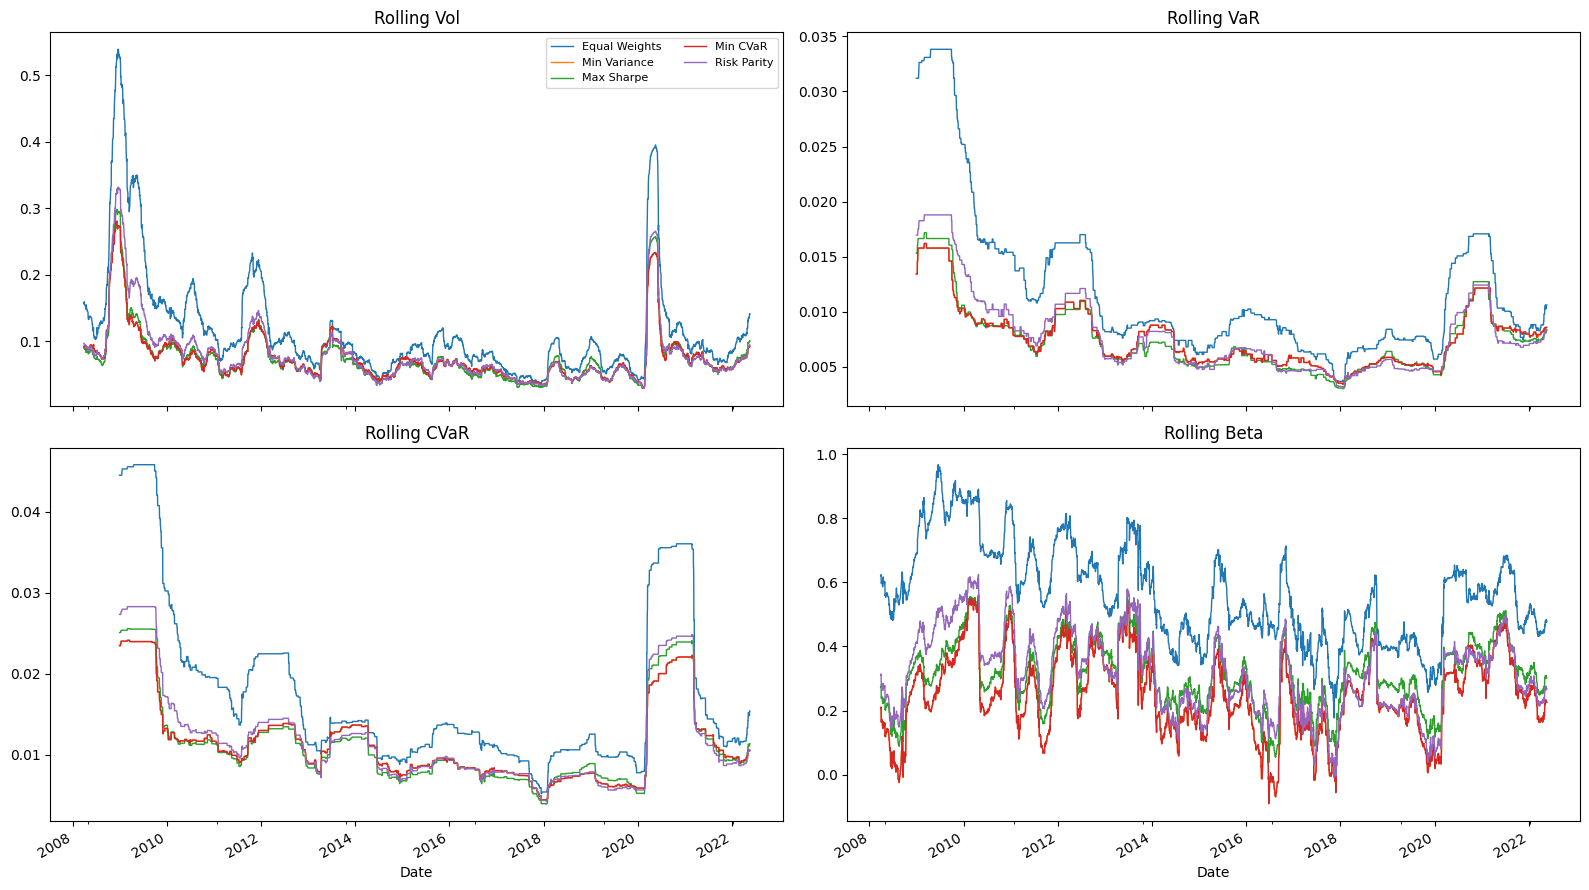

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
for ax, (name, df) in zip(axes.flat, metrics.items()):
    df.plot(ax=ax, lw=1, legend=False)
    ax.set_title(f'Rolling {name}')

axes[0, 0].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## Module 6 - Historical Stress Testing

In [12]:
net_returns_df = pd.DataFrame({name: friction(daily_returns, w)['net_returns'] for name, w in weights_strat.items()})
net_returns_df.index = pd.to_datetime(daily_returns.index)

full_growth = (1 + net_returns_df).cumprod()

scenarios = {
    '2008' : ('2008-01-01', '2009-01-01'),
    '2020' : ('2020-01-01', '2021-01-01'),
    '2022' : ('2022-01-01', '2023-01-01')
}
stress_results = []

for sc, (start, end) in scenarios.items():
    window = net_returns_df.loc[start:end]
    if window.empty: continue

    for strat in window.columns:
        rets = window[strat]

        global_drawdown = full_growth / full_growth.cummax() - 1
        drawdown = global_drawdown.loc[start:end]
        trough_date = drawdown.idxmin()


        strat_trough_date = trough_date[strat]
        peak_date = full_growth.loc[:strat_trough_date, strat].idxmax()
        peak_val = full_growth.loc[peak_date, strat]

        future_growth = full_growth.loc[strat_trough_date:, strat]

        recovered_signals = np.where(future_growth >= peak_val)[0]

        if len(recovered_signals) > 0:
            recovery_date = future_growth.index[recovered_signals[0]]

            rec_time = len(net_returns_df.loc[peak_date:recovery_date]) - 1
        else:
            rec_time = np.nan

        stress_results.append({
            'Strategy': strat,
            f'{sc} Return': (1 + rets).prod() - 1,
            f'{sc} Worst Day': rets.min(),
            f'{sc} Max DD': drawdown[strat].min(),
            f'{sc} Peak-to-Recovery (Days)': rec_time
        })

stress_df = pd.DataFrame(stress_results).groupby('Strategy').first()
recovery_cols = [c for c in stress_df.columns if 'Recovery' in c]
stress_df[recovery_cols] = stress_df[recovery_cols].apply(pd.to_numeric, errors='coerce')

fmt = {c: '{:.2%}' if 'Recovery' not in c else '{:.0f}' for c in stress_df.columns}
stress_df.style.format(fmt, na_rep="Not Recovered")


,2008 Return,2008 Worst Day,2008 Max DD,2008 Peak-to-Recovery (Days),2020 Return,2020 Worst Day,2020 Max DD,2020 Peak-to-Recovery (Days),2022 Return,2022 Worst Day,2022 Max DD,2022 Peak-to-Recovery (Days)
Strategy,,,,,,,,,,,,
Equal Weights,-21.54%,-8.35%,-38.71%,478,11.28%,-7.89%,-23.56%,110,-14.43%,-3.25%,-22.11%,543
Max Sharpe,-9.69%,-4.27%,-22.45%,350,16.43%,-6.35%,-14.98%,68,-11.35%,-2.61%,-16.97%,491
Min CVaR,-6.63%,-4.53%,-20.60%,388,16.79%,-5.99%,-13.64%,62,-10.23%,-2.53%,-16.34%,523
Min Variance,-6.59%,-4.53%,-20.57%,388,16.80%,-5.98%,-13.62%,62,-10.22%,-2.53%,-16.33%,523
Risk Parity,-10.41%,-5.18%,-25.86%,354,12.90%,-6.62%,-16.15%,74,-11.88%,-2.66%,-18.50%,543


## Module 7 - OOS Portfolio Validation

In [13]:
test_mu = test_returns.mean() * 252
test_cov = test_returns.cov() * 252

oos_summary = []
for name, weight in weights_strat.items():
    var, cvar = portfolio_risk(test_returns, weight)
    ann_ret, ann_vol, ann_sharpe, max_dd = portfolio_performance(test_returns, weight, test_mu, test_cov)

    row_dict = {'Strategy' : name}
    row_dict.update({
        'Daily VaR (95%)' : var,
        'Daily CVaR (95%)' : cvar,
        'Max Drawdown' : max_dd,
        'Annualized Mean Return' : ann_ret,
        'Annual Volatility' : ann_vol,
        'Annual Sharpe' : ann_sharpe
    })
    oos_summary.append(row_dict)

oos_sample_df = pd.DataFrame(oos_summary).set_index('Strategy')
formats = {col : '{:.2%}' for col in oos_sample_df.columns}
formats['Annual Sharpe'] = '{:.2f}'
oos_sample_df.style.format(formats)


,Daily VaR (95%),Daily CVaR (95%),Max Drawdown,Annualized Mean Return,Annual Volatility,Annual Sharpe
Strategy,,,,,,
Equal Weights,1.10%,1.55%,-14.83%,12.88%,11.39%,1.13
Min Variance,0.80%,1.17%,-10.63%,14.22%,8.90%,1.60
Max Sharpe,0.81%,1.20%,-10.77%,13.82%,8.96%,1.54
Min CVaR,0.80%,1.17%,-10.63%,14.21%,8.90%,1.60
Risk Parity,0.85%,1.21%,-12.22%,11.95%,9.04%,1.32


### VaR Model Validation
$$
\text {Likelihood Ratio (Probability of Failure)}
\\
lr_{pof} = -2 \ln \left[ \frac {(1-p)^{N-x}.p^x} {(1-\hat {p})^{N-x}.\hat {p}^x} \right]
$$

In [14]:
def var_backtest(returns, var, c=0.95):
    n_days = len(returns)
    p = 1 - c  # Expected Failure Probability
    x = (returns < -var).sum()  # numbers of failure
    p_hat = x / n_days  # Observed Failure days

    if x == 0:
        lr_pof = -2 * n_days * np.log(1 - p)
    elif x == n_days:
        lr_pof = -2 * n_days * np.log(p)
    else:
        null_log = ((n_days - x) * np.log(1 - p)) + (x * np.log(p))
        alt_log = ((n_days - x) * np.log(1 - p_hat)) + (x * np.log(p_hat))
        lr_pof = -2 * (null_log - alt_log)

    p_value = 1 - stat.chi2.cdf(lr_pof, df=1)

    if p_value < 0.05:
        status = 'Under-risked' if p_hat > p else 'Over-risked'
    else:
        status = 'Fail to Reject'

    return n_days, x, p_hat, p_value, status

backtest_res = []
for name, weight in weights_strat.items():
  train_ret = train_returns @ weight
  test_ret = test_returns @ weight
  var = -np.quantile(train_ret, 0.05)
  n_days, x, p_hat, p_value, status = var_backtest(test_ret, var)

  backtest_res.append({
    'Strategy' : name,
    'VaR Forecast' : f'{var:.2%}',
    'Total Days' : n_days,
    'VaR Breaches' : x,
    'Observed Failure Rate' : f'{p_hat:.2%}',
    'Kupiec p-value' : f'{p_value:.4f}',
    'Calibration Status' : status
  })

backtest_df = pd.DataFrame(backtest_res).set_index('Strategy')
backtest_df

,VaR Forecast,Total Days,VaR Breaches,Observed Failure Rate,Kupiec p-value,Calibration Status
Strategy,,,,,,
Equal Weights,1.28%,906,31,3.42%,0.0211,Over-risked
Min Variance,0.81%,906,44,4.86%,0.8422,Fail to Reject
Max Sharpe,0.80%,906,48,5.30%,0.6834,Fail to Reject
Min CVaR,0.81%,906,44,4.86%,0.8422,Fail to Reject
Risk Parity,0.85%,906,44,4.86%,0.8422,Fail to Reject


In [15]:
oos_dashboard_res = {}
for name, weight in weights_strat.items():
    res = friction(test_returns, weight)
    oos_dashboard_res[name] = {
        'Daily Rebalanced (Gross)': (1 + test_returns @ weight).prod() - 1,
        'Monthly Rebal (Gross)':       res['cum_gross'],
        'Monthly Rebal (Net)':         res['cum_net'],
        'Pure Buy & Hold (Gross)':     (1 + test_returns).prod() @ weight - 1,
        'Ann. Turnover (One-Way)':     res['annual_turnover'],
        'Max Drawdown (Net)':          res['max_drawdown'],
        'Max Asset Drift':             res['max_drift'],
        'Avg Asset Drift':             res['avg_drift']
    }

oos_friction_df = pd.DataFrame(oos_dashboard_res).T
oos_friction_df.style.format('{:.2%}')

,Daily Rebalanced (Gross),Monthly Rebal (Gross),Monthly Rebal (Net),Pure Buy & Hold (Gross),Ann. Turnover (One-Way),Max Drawdown (Net),Max Asset Drift,Avg Asset Drift
Equal Weights,55.23%,54.39%,54.32%,58.69%,12.55%,-14.84%,2.23%,0.32%
Min Variance,64.35%,63.57%,63.50%,69.78%,11.62%,-10.66%,2.99%,0.30%
Max Sharpe,61.96%,61.14%,61.07%,66.72%,11.61%,-10.83%,2.73%,0.30%
Min CVaR,64.32%,63.54%,63.47%,69.74%,11.62%,-10.65%,2.99%,0.30%
Risk Parity,51.41%,50.65%,50.59%,56.36%,11.64%,-12.24%,2.38%,0.30%


## Module 8 - Benchmarking, Attribution & Strategy Comparison

In [16]:
def period_metrics(ret, w_strat, eq_key):
  benchmark_ret = ret @ w_strat[eq_key]
  ann_bench_ret = benchmark_ret.mean() * 252

  records = []
  for name, weight in w_strat.items():
    if name == eq_key:
      continue

    strat_ret = ret @ weight
    ann_strat_ret = strat_ret.mean() * 252

    active_ret = ann_strat_ret - ann_bench_ret
    tracking_error = (strat_ret - benchmark_ret).std() * np.sqrt(252)
    info_ratio = active_ret / tracking_error
    rf = 0.0   # Assumed annual risk-free rate
    sharpe_ratio = (ann_strat_ret - rf)/ (strat_ret.std() * np.sqrt(252))

    records.append({
        'Strategy' : name,
        'Active Return' : active_ret,
        'Tracking Error' : tracking_error,
        'Information Ratio' : info_ratio,
        'Sharpe Ratio' : sharpe_ratio
    })
  return pd.DataFrame(records).set_index('Strategy')


eq_key = [k for k in weights_strat.keys() if 'equal' in k.lower()][0]

is_df = period_metrics(train_returns, weights_strat, eq_key)
oos_df = period_metrics(test_returns, weights_strat, eq_key)

degradation_df = pd.concat({'In-Sample (IS)': is_df, 'Out-of-Sample (OOS)': oos_df}, axis=1)

formats = {col: '{:.2f}' if 'ratio' in col[1].lower() else '{:.2%}' for col in degradation_df.columns}
print(f'Benchmark Return (IS) = {((train_returns @ weights_strat[eq_key]).mean() * 252):.2%}')
print(f'Benchmark Return (OOS) = {((test_returns @ weights_strat[eq_key]).mean() * 252):.2%}')
degradation_df.style.format(formats)

Benchmark Return (IS) = 7.50%
Benchmark Return (OOS) = 12.88%


In [17]:
contribution_records = []

for name, weight in weights_strat.items():
  asset_contrib = weight * test_returns.mean() * 252

  row_dict = {'Strategy' : name}
  row_dict.update({f'{t} Contribution' : asset_contrib[t] for t in test_returns.columns})
  row_dict['Total OOS Return'] = asset_contrib.sum()

  contribution_records.append(row_dict)

contrib_df = pd.DataFrame(contribution_records).set_index('Strategy')
contrib_df.style.format('{:.2%}')

,BND Contribution,EFA Contribution,GLD Contribution,SPY Contribution,VNQ Contribution,Total OOS Return
Strategy,,,,,,
Equal Weights,0.56%,2.88%,4.91%,3.70%,0.84%,12.88%
Min Variance,1.13%,0.00%,8.10%,4.99%,0.00%,14.22%
Max Sharpe,1.13%,0.00%,6.47%,6.22%,0.00%,13.82%
Min CVaR,1.13%,0.00%,8.08%,5.00%,0.00%,14.21%
Risk Parity,1.13%,1.76%,6.18%,2.50%,0.38%,11.95%


In [18]:
combined_df = pd.concat([in_sample_df, oos_sample_df], axis=1, keys=['In-Sample', 'Out-of-Sample'])

col_fmts = {}
for col in combined_df.columns:
    if 'Sharpe' in col[1]:
        col_fmts[col] = '{:.2f}'
    else:
        col_fmts[col] = '{:.2%}'

combined_df.style.format(col_fmts)


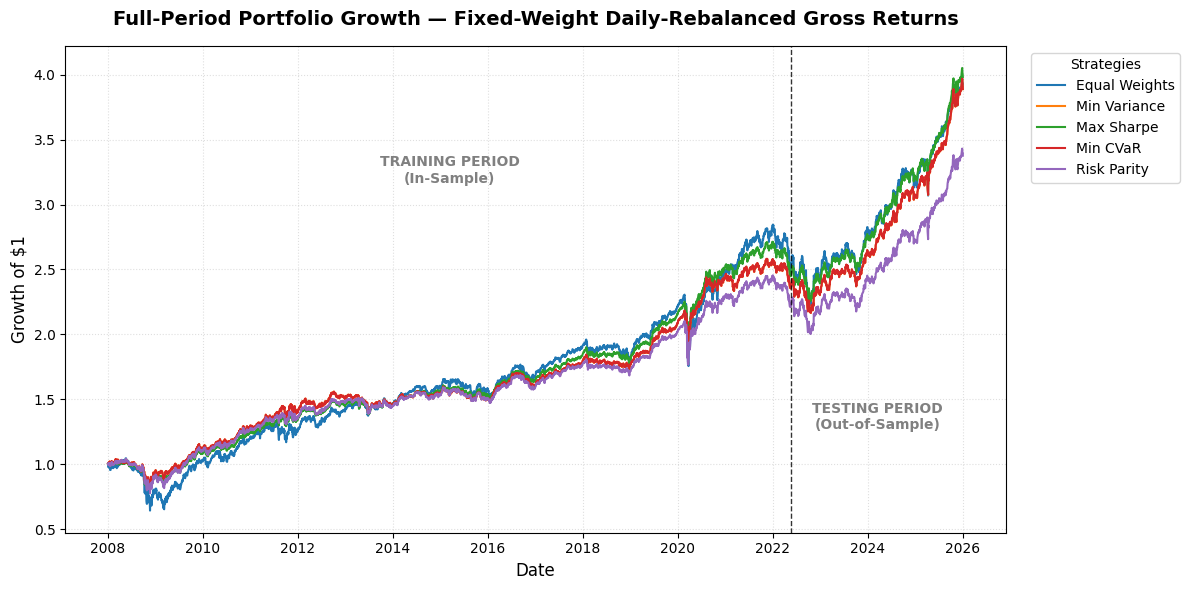

In [19]:
fig, ax = plt.subplots(figsize = (12, 6))

for name, weight in weights_strat.items():
  train_ret = train_returns @ weight
  test_ret = test_returns @ weight

  full_ret = pd.concat([train_ret, test_ret])
  full_cum_growth = (1 + full_ret).cumprod()

  ax.plot(full_cum_growth.index, full_cum_growth, label=name, linewidth=1.5)

split_date = train_returns.index[-1]
ax.axvline(split_date, color='black', linestyle='--', linewidth=1, alpha=0.8)

y_max = ax.get_ylim()[1]
ax.text(train_returns.index[len(train_returns)//2], y_max * 0.8, 'TRAINING PERIOD\n(In-Sample)',
        fontsize=10, fontweight='semibold', ha='center', va='top', color='gray')
ax.text(test_returns.index[len(test_returns)//2], y_max * 0.35, 'TESTING PERIOD\n(Out-of-Sample)',
        fontsize=10, fontweight='semibold', ha='center', va='top', color='gray')

ax.set_title('Full-Period Portfolio Growth — Fixed-Weight Daily-Rebalanced Gross Returns', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Growth of $1', fontsize=12)

ax.grid(True, linestyle=':', alpha=0.4)
ax.legend(title='Strategies', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## Module 9 - Portfolio Risk Limits & Final Dashboard

In [20]:
top_contributors = {}
for name, weight in weights_strat.items():
  pct_contrib = risk_composition(weight, train_cov)
  top_asset = train_returns.columns[np.argmax(pct_contrib)]
  top_contributors[name] = f'{top_asset} ({np.max(pct_contrib):.1%})'

final_dashboard = pd.DataFrame({
    'Annualized Mean Return': in_sample_df['Annualized Mean Return'],
    'Ann. Volatility': in_sample_df['Annual Volatility'],
    'Sharpe Ratio': in_sample_df['Annual Sharpe'],
    'Daily VaR (95%)': in_sample_df['Daily VaR (95%)'],
    'Daily CVaR (95%)': in_sample_df['Daily CVaR (95%)'],
    'Max Drawdown': in_sample_df['Max Drawdown'],
    'Max Asset Weight' : weight_df.max(axis=1),
    'Top Risk Contributor': pd.Series(top_contributors),
    'OOS Annualized Return': oos_sample_df['Annualized Mean Return'],
    'OOS Sharpe': oos_sample_df['Annual Sharpe']
})

bench_name = [idx for idx in in_sample_df.index if 'equal' in idx.lower()][0]
MAX_VOL = float(in_sample_df.loc[bench_name, 'Annual Volatility'] + 0.05)
MAX_D_VaR = float(in_sample_df.loc[bench_name, 'Daily VaR (95%)'] + 0.005)
MAX_D_CVaR = float(in_sample_df.loc[bench_name, 'Daily CVaR (95%)'] + 0.005)
MAX_DD = abs(float(in_sample_df.loc[bench_name, 'Max Drawdown'])) + 0.05
MAX_WEIGHT = 0.40

is_passing = (
    (final_dashboard['Ann. Volatility'] <= MAX_VOL) &
    (final_dashboard['Daily VaR (95%)'] <= MAX_D_VaR) &
    (final_dashboard['Daily CVaR (95%)'] <= MAX_D_CVaR) &
    (final_dashboard['Max Drawdown'].abs() <= MAX_DD) &
    (final_dashboard['Max Asset Weight'] <= MAX_WEIGHT))

final_dashboard['Risk Limits Status'] = np.where(
    is_passing, '🟢 PASS', '🔴 BREACH')

print("                                 FINAL MONITORING DASHBOARD                               ")
dashboard_formats = {col: '{:.2%}' for col in final_dashboard.columns if 'Sharpe' not in col and 'Status' not in col and 'Contributor' not in col}
dashboard_formats.update({'Sharpe Ratio': '{:.2f}', 'OOS Sharpe': '{:.2f}'})
display(final_dashboard.style.format(dashboard_formats))

print("\n                                STRATEGY WEIGHT ALLOCATION                               ")
weight_df.style.format('{:.2%}')

                                 FINAL MONITORING DASHBOARD                               


,Annualized Mean Return,Ann. Volatility,Sharpe Ratio,Daily VaR (95%),Daily CVaR (95%),Max Drawdown,Max Asset Weight,Top Risk Contributor,OOS Annualized Return,OOS Sharpe,Risk Limits Status
Equal Weights,7.50%,14.65%,0.51,1.28%,2.26%,-38.54%,20.00%,VNQ (38.4%),12.88%,1.13,🟢 PASS
Min Variance,6.36%,8.60%,0.74,0.81%,1.27%,-19.85%,40.00%,GLD (50.8%),14.22%,1.60,🟢 PASS
Max Sharpe,6.64%,8.79%,0.76,0.80%,1.30%,-21.91%,40.00%,SPY (61.7%),13.82%,1.54,🟢 PASS
Min CVaR,6.36%,8.60%,0.74,0.81%,1.27%,-19.87%,40.00%,GLD (50.6%),14.21%,1.60,🟢 PASS
Risk Parity,6.04%,9.59%,0.63,0.85%,1.43%,-25.49%,40.00%,GLD (26.0%),11.95%,1.32,🟢 PASS



                                STRATEGY WEIGHT ALLOCATION                               


,BND Weight (%),EFA Weight (%),GLD Weight (%),SPY Weight (%),VNQ Weight (%)
Equal Weights,20.00%,20.00%,20.00%,20.00%,20.00%
Min Variance,40.00%,0.00%,33.05%,26.95%,0.00%
Max Sharpe,40.00%,0.00%,26.37%,33.63%,0.00%
Min CVaR,40.00%,0.00%,32.95%,27.05%,0.00%
Risk Parity,40.00%,12.27%,25.21%,13.50%,9.02%
